# **Analyzing Chilean Parliamentary Speeches**

A Proof-of-Concept Using NLP Methods

**1. Introduction**

Parliamentary speeches offer a rich source of information for understanding legislative priorities, party positions, and policy debates. This demo project aims to showcase a workflow that collects, preprocesses, and analyzes a sample of speeches from Chilean political representatives.

**1.1 Project Goals**

- NLP Pipeline: Demonstrate how to clean and tokenize Spanish-language text, remove stop words, and prepare data for advanced analysis.
- Topic Modeling: Automatically group speeches by topic to uncover recurring themes.
- Sentiment and Entity Analysis: Extract sentiment scores and named entities (people, places, organizations) to gauge how discussion themes might vary.
- Policy Insight: Present a high-level overview of how data science techniques can guide policy research, focusing on legislative discussions related to law enforcement, security, etc.

**1. 2 Why This Matters**

Understanding the content and tone of parliamentary speeches can yield:

- Transparency: Identify which issues are emphasized the most.
- Accountability: See how representatives align with or diverge from their party lines.
- Policy Refinement: Spot emerging topics or sentiments that might shape new legislation.



---



2. **Data Description**

This project leverages two comprehensive datasets to analyze legislative activity in Chile, capturing both the spoken contributions of deputies and their political profiles:

Speeches Dataset (extracted_speeches.csv):

  - This dataset contains detailed records of speeches delivered during legislative sessions. Each row represents a single speech.

    Key Columns:
      - full_name: The full name of the deputy delivering the speech.
        role: The role or title of the speaker during the session (e.g., President, Vice President).
      - Speech: The complete transcription of the deputy's speech, providing insights into legislative discussions and rhetoric.

Deputies Dataset (chilean_deputies_classified.csv):

  - This dataset provides detailed profiles for each deputy, including their political affiliations and regional representation. Each row corresponds to one deputy.
   
    Key Columns:
      - full_name: The deputy’s complete name.
      - URL: A link to additional information about the deputy, such as their official profile or voting record.
      - Comunas: The municipalities or communities represented by the deputy.
      - Distrito: The district represented by the deputy.
      - Región: The geographical region associated with the deputy's representation.
      - Período: The term or period during which the deputy serves.
      - Partido: The deputy’s political party affiliation.
      - Bancada: The parliamentary group or caucus to which the deputy belongs.
      - Political_Category: The broader political alignment of the deputy (e.g., Center-Left, Right Wing, Government Alliance).





---




3. **Methodology Overview**

This analysis follows a structured workflow from data collection to interpretation:

1.  Data Collection:
- Deputy metadata (party affiliation, region, demographics) was scraped from official parliamentary websites to link speeches to deputies.

2.    Preprocessing:
-   Text was cleaned (lowercased, punctuation/numbers removed, stopwords filtered) and tokenized into words.

3.    Exploratory Analysis:
- Analyzed speech counts, top speakers, and word frequencies, visualized with bar charts.

4. Topic Modeling (LDA):
-   Transformed text into a document-term matrix and applied Latent Dirichlet Allocation to uncover recurring themes, evaluated with coherence scores.

5. NER and Sentiment Analysis:
-   Used a Spanish language model to extract entities (e.g., persons, organizations) and analyze sentiment.

6.  TF-IDF Analysis:
-   Highlighted distinctive words across political groups, comparing language usage by affiliation.

7.  Visualization:
-  Plotted topic distributions, word frequencies, and key insights for reporting.



---



4. Next Steps

- **Handle Multiple Laws Automatically:**
Currently, the analysis is limited to a single law or dataset at a time. In the future, this project can be enhanced so that users simply input the law they wish to study. By integrating Selenium or similar automation tools, the system could handle large-scale data retrieval seamlessly, scraping multiple laws’ transcripts in one session.

- **Process Large Legislative PDFs:**
Much of the relevant parliamentary discourse is contained in lengthy PDFs—especially in the “Discusión en Sala” sections. A next step would be to filter and parse only the relevant “Discusión en Sala” pages. This would provide more precise and domain-specific data for NLP analysis without extra noise.

- **Incorporate Voting Records:**
Linking speeches to deputies’ voting records could deepen the insights. By combining textual features (what they say) with voting patterns (how they vote), we can build predictive or explanatory models—e.g., to see if certain language usage correlates with a particular voting stance or if there are patterns of party alignment versus individual positions.

- **Expansion to Other Chambers and Longer Time Series.**
The current data focuses on one chamber or a limited set of debates. In the future, including Senate transcripts (or other legislative bodies) could reveal differences in focus or rhetoric. Similarly, a longer historical timeframe could show how discourse evolves around recurring policy issues and how party alignment shifts over multiple legislative cycles.

- **Deeper and Custom Analyses:**
Finally, there is potential for more sophisticated NLP approaches (e.g., stance detection, advanced topic modeling, domain-specific sentiment analysis) and richer data integration (e.g., merging socio-economic indicators or public opinion polls). As this proof-of-concept evolves, these methods will allow for even more nuanced insights into legislative behavior and policy discourse.



---



# 5. **Appendix**: Code & Technical Details

Below you will find the complete code used to run the analyses. Readers primarily interested in the results can skip this section, while those who want to replicate or inspect the methodology in detail can follow along.

## Setting and scrapping

new


In [ ]:
# Run this in one cell, *before* any imports:
%pip install --upgrade --force-reinstall numpy==1.24.3


  Using cached numpy-1.24.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.6 kB)
Using cached numpy-1.24.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jaxlib 0.5.1 requires numpy>=1.25, but you have numpy 1.24.3 which is incompatible.
jaxlib 0.5.1 requires scipy>=1.11.1, but you have scipy 1.10.1 which is incompatible.
scikit-image 0.25.2 requires scipy>=1.11.4, but you have scipy 1.10.1 which is incompatible.
pymc 5.22.0 requires numpy>=1.25.0, but you have numpy 1.24.3 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 1.24.3 which is incompatible.
treescope 0.1.9 requires num

In [ ]:
%pip install --upgrade --force-reinstall \
  scipy==1.10.1 \
  scikit-learn==1.3.2 \
  gensim==4.3.3 \
  spacy==3.5.4


  Using cached scipy-1.10.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
  Using cached scikit_learn-1.3.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
  Using cached gensim-4.3.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (8.1 kB)
  Using cached spacy-3.5.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (25 kB)
  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached joblib-1.5.0-py3-none-any.whl.metadata (5.6 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached smart_open-7.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached spacy_legacy-3.0.12-py2.py3-none-any.whl.metadata (2.8 kB)
  Using cached spacy_loggers-1.0.5-py3-none-any.whl.metadata (23 kB)
  Using cached murmurhash-1.0.12-cp311-cp311-manylinux_2_5_x86_64.manylinux1_x86_64.manylinux_2_17_x86_64.manylinux2014_x86_64.whl.me

In [1]:
# 1. Install the Spanish model
!python -m spacy download es_core_news_sm

d:\Users\jorge\anaconda3\python.exe: No module named spacy


In [ ]:
!pip install unidecode requests matplotlib seaborn beautifulsoup4 unidecode nltk PyPDF2 spacytextblob

^C


In [2]:
import requests
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
import re
from unidecode import unidecode
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import PyPDF2
import spacy
from spacytextblob.spacytextblob import SpacyTextBlob
import gensim
from gensim.models import CoherenceModel
import gensim.corpora as corpora
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
import seaborn as sns
import unicodedata

ModuleNotFoundError: No module named 'PyPDF2'

### Scraping the Deputies' information:


Scrape the main page of the [Chilean Cámara de Diputados](https://www.camara.cl/diputados/diputados.aspx#mostrarDiputados) to extract the names and URLs of each deputy. This will provide a list of political representatives whose speeches we will later analyze.

Visit each deputy's individual page and scrape additional information such as their political party (Partido), district (Distrito), municipality (Comuna), and parliamentary group (Bancada). This metadata will be used to enrich the analysis of their speeches.

Also create the political coalitions:
*   Guberment coalition (Alianza de Gobierno)
*   Other left parties (Partido Humanista)
*   Center (Centro)
*   Center-right wing coalition (Chile Vamos)
*   Right wing (Derecha)

* Independents still have to be classified for coalitions

In [3]:
def clean_name(name):
    prefixes = ["Diputado", "Diputada", "Sr.", "Sra.", "Srta."]
    for prefix in prefixes:
        if prefix in name:
            name = name.replace(prefix, "").strip()
    return name

def normalize_url(url):
    base_url = "https://www.camara.cl"
    if url.startswith("/"):
        url = base_url + url
    elif not url.startswith("http"):
        url = base_url + "/" + url
    if '/diputados/' not in url:
        url = url.replace("/detalle/", "/diputados/detalle/")
    return url

def fetch_page(url):
    try:
        response = requests.get(url)
        response.raise_for_status()
        return BeautifulSoup(response.content, 'html.parser')
    except requests.RequestException as e:
        print(f"Error fetching {url}: {e}")
        return None

def extract_deputy_links(soup):
    return soup.find_all('a', href=lambda x: x and 'detalle/mociones.aspx' in x)

def scrape_deputy_profile(deputy):
    soup = fetch_page(deputy['URL'])
    if not soup:
        return deputy

    name_tag = soup.find('h1', class_='rotulo') or soup.find('h2', class_='rotulo')
    if name_tag:
        deputy['Full Name'] = clean_name(name_tag.text.strip())

    info_div = soup.find('div', class_='grid-3 aleft m-left14', style='margin-right: 20px;')
    if info_div:
        info_text = info_div.get_text(strip=True)

        patterns = {
            'Comunas': r'Comunas:\s*(.*?)(?=Distrito|$)',
            'Distrito': r'Distrito:\s*(.*?)(?=Región|$)',
            'Región': r'Región:\s*(.*?)(?=Período|$)',
            'Período': r'Período:\s*(.*?)(?=Partido|$)',
            'Partido': r'Partido:\s*(.*?)(?=Bancada|$)',
            'Bancada': r'Bancada:\s*(.*?)(?=$)'
        }

        for key, pattern in patterns.items():
            match = re.search(pattern, info_text)
            if match:
                deputy[key] = match.group(1).strip()

    return deputy

def scrape_deputies_main_page(url):
    soup = fetch_page(url)
    if not soup:
        return []

    deputies = extract_deputy_links(soup)
    deputy_list = [{'Name': clean_name(d.text.strip()), 'URL': normalize_url(d['href'])} for d in deputies if d.text.strip()]
    return list({d['URL']: d for d in deputy_list}.values())  # Remove duplicates

def main():
    main_url = "https://www.camara.cl/diputados/diputados.aspx#mostrarDiputados"
    deputies = scrape_deputies_main_page(main_url)
    print(f"Found {len(deputies)} unique deputies")

    with ThreadPoolExecutor(max_workers=10) as executor:
        future_to_deputy = {executor.submit(scrape_deputy_profile, deputy): deputy for deputy in deputies}
        for future in as_completed(future_to_deputy):
            deputy = future_to_deputy[future]
            try:
                data = future.result()
                print(f"Scraped data for: {data.get('Full Name', data['Name'])}")
            except Exception as exc:
                print(f"{deputy['Name']} generated an exception: {exc}")

    df = pd.DataFrame(deputies)

    # Save to CSV
    df.to_csv('chilean_deputies_raw.csv', index=False)
    print("Raw data saved to chilean_deputies_raw.csv")

    return df  # Return the DataFrame

if __name__ == "__main__":
    df_deputies = main()

Found 156 unique deputies


NameError: name 'ThreadPoolExecutor' is not defined

independents:

In [ ]:
def analyze_independents(csv_file):
    # Read the CSV file
    df = pd.read_csv(csv_file)

    # Count total number of deputies
    total_deputies = len(df)

    # Filter independents
    independents = df[df['Partido'] == 'Independientes']

    # Count independents
    total_independents = len(independents)

    # Count independents with a bancada
    independents_with_bancada = independents[independents['Bancada'].notna() & (independents['Bancada'] != '')]
    total_independents_with_bancada = len(independents_with_bancada)

    # Print results
    print(f"Total number of deputies: {total_deputies}")
    print(f"Total number of independents: {total_independents}")
    print(f"Number of independents with a bancada: {total_independents_with_bancada}")

    # Print percentage of independents
    percentage_independents = (total_independents / total_deputies) * 100
    print(f"Percentage of independents: {percentage_independents:.2f}%")

    # Print percentage of independents with bancada
    percentage_with_bancada = (total_independents_with_bancada / total_independents) * 100 if total_independents > 0 else 0
    print(f"Percentage of independents with a bancada: {percentage_with_bancada:.2f}%")

    # List independents and their bancadas
    print("\nList of independents and their bancadas:")
    for _, deputy in independents.iterrows():
        bancada = deputy['Bancada'] if pd.notna(deputy['Bancada']) else 'No bancada'
        print(f"{deputy['Full Name']}: {bancada}")

    # Count independents by bancada
    bancada_counts = independents['Bancada'].value_counts()
    print("\nDistribution of independents across bancadas:")
    print(bancada_counts)

if __name__ == "__main__":
    csv_file = 'chilean_deputies_raw.csv'  # Make sure this matches your CSV file name
    analyze_independents(csv_file)

Classification by parties and bancadas (for independents)

In [ ]:
def categorize_party_and_bancada(row):
    party = row['Partido']
    bancada = row['Bancada']

    alianza_gobierno = [
        "Partido Comunista", "Partido Por la Democracia", "Partido Socialista",
        "Frente Amplio", "Partido Liberal de Chile", "Partido Acción Humanista",
        "Partido Radical de Chile", "Federación Regionalista Verde Social"
    ]
    center_right = ["Renovación Nacional", "Evolución Política"]
    right_wing = ["Unión Demócrata Independiente", "Partido Republicano", "Partido Social Cristiano"]
    center = ["Partido Demócrata Cristiano", "Movimiento Amarillos por Chile", "Partido Demócratas Chile"]

    # Classify based on party
    if party in alianza_gobierno:
        return "Alianza de Gobierno"
    elif party in center_right:
        return "Center-Right"
    elif party in right_wing:
        return "Right Wing"
    elif party in center:
        return "Center"

    # If independent, classify based on bancada
    if party == "Independientes":
        bancada_classifications = {
            "Partido Por la Democracia": "Alianza de Gobierno",
            "Comité Republicanos": "Right Wing",
            "Comité Demócratas, Amarillos e Independientes": "Center",
            "Renovación Nacional": "Center-Right",
            "Comité Social Cristiano e Independientes": "Right Wing",
            "Comité DC e Independientes": "Center",
            "Frente Amplio e Independientes": "Alianza de Gobierno",
            "Comité Mixto Radical - Liberal": "Alianza de Gobierno",
            "Evolución Política": "Center-Right",
            "Unión Demócrata Independiente": "Right Wing",
            "Socialista": "Alianza de Gobierno",
            "Comité Comunista, Federación Regionalista Verde Social, Acción Humanista e Independientes": "Alianza de Gobierno"
        }
        return bancada_classifications.get(bancada, "Unknown")

    return "Unknown"

def classify_deputies(df):
    df['Political_Category'] = df.apply(categorize_party_and_bancada, axis=1)

    # Save classified data to CSV
    df.to_csv('chilean_deputies_classified.csv', index=False)
    print("Classified data saved to chilean_deputies_classified.csv")

    # Print category distribution
    print("\nDistribution of Political Categories:")
    print(df['Political_Category'].value_counts())

    # Check for unknown categories
    unknown_deputies = df[df['Political_Category'] == 'Unknown']
    if not unknown_deputies.empty:
        print("\nDeputies in the Unknown category:")
        for _, deputy in unknown_deputies.iterrows():
            print(f"Name: {deputy['Full Name']}, Party: {deputy['Partido']}, Bancada: {deputy['Bancada']}")
    else:
        print("\nNo deputies in the Unknown category.")

    return df

if __name__ == "__main__":
    # Load the raw data
    df_raw = pd.read_csv('chilean_deputies_raw.csv')
    df_classified = classify_deputies(df_raw)

### Choosing law and extracting speech text from transcriptions:

Law Selection Script

This script allows users to choose between analyzing the default **Naín-Retamal Law** or another law by specifying a different Google Drive link.
By default, the script will use the Naín-Retamal Law for analysis. To switch to another law, simply replace the `selected_law_link` variable
with the Google Drive link of the other law's PDF.

Pre-loaded Laws:
1. Naín-Retamal and Antiterrorist laws (Default Law)
I selected these two laws as defaults because they both address public security and enforcement—topics frequently discussed together in the Chilean Congress. The Naín-Retamal Law focuses on legal protections for law enforcement officials, while the Antiterrorist Law outlines measures against terrorism-related activities.
2. Law N° 21.533 (Constitution Drafting Law)
This law amends the Political Constitution of the Republic to establish a procedure for the creation and approval of a new Constitution. It is a key piece of legislation that defines how Chile can restructure its fundamental legal framework, ensuring a clear process for shaping and ratifying constitutional reforms.

How It Works:
- The script downloads the selected PDF, merges the required pages, and prepares it for further text analysis.

In [ ]:
# Default and optional law links
nain_antiterror_link = "https://drive.google.com/uc?id=1d0GkfuIWQl3u2R9nbjPjdbO4MmmjV37t"
new_constitutión_link = "https://drive.google.com/uc?id=1QxkD5T2vsLoWr0ujPW8cXjD4pidiGwBP"
autismprotection_link = "https://drive.google.com/uc?id=1ac__CScWbiPVU5kAv1VOh2pOwJunONhm"
terroristbehaviour_link = "https://drive.google.com/uc?id=1CnUtmdrIS_R2RIdBJDPu1j3mKaUBf2Of"


# User selection: By default, Naín-Retamal and antiterror Law is selected
selected_law_link = terroristbehaviour_link

# File name for the downloaded law
output_pdf_path = "selected_law.pdf"


In [ ]:
# Function to download the selected law
def download_law_file(google_drive_url, output_path):

    response = requests.get(google_drive_url)
    if response.status_code == 200:
        with open(output_path, 'wb') as file:
            file.write(response.content)
        print(f"Law successfully downloaded and saved as '{output_path}'.")
    else:
        print(f"Failed to download the file. Status code: {response.status_code}")

# Call the function to download the selected law
download_law_file(selected_law_link, output_pdf_path)

### Preprocessing of the pdfs

### Extraction and cleaning of speeches

Extract and clean this text, assigning each segment to the appropriate speaker based on metadata (names, titles, or roles) present in the transcription.

In [ ]:
def clean_text(text):
    # Remove the header and the bcn.cl text
    patterns_to_remove = [
        r"Historia de la Ley N° 21\.560\s*Página\s*\d+\s*de\s*\d+\s*Discusión en Sala",
        r"Biblioteca del Congreso Nacional de Chile - www\.bcn\.cl/historiadelaley - documento generado el \d+-\w+-\d+"
    ]


    for pattern in patterns_to_remove:
        text = re.sub(pattern, "", text)

    return text.strip()

def extract_speech_text(pdf_path):
    speeches = []
    current_speaker = ""
    current_speech = ""
    total_text = ""

    try:
        with open(pdf_path, 'rb') as file:
            reader = PyPDF2.PdfReader(file)
            total_pages = len(reader.pages)

            print(f"Total pages in PDF: {total_pages}")
            print(f"Analyzing all pages")

            for page_num in range(total_pages):
                if page_num % 10 == 0:  # Print progress every 10 pages
                    print(f"Processing page {page_num + 1}")

                page = reader.pages[page_num]
                text = page.extract_text()
                if text:
                    text = clean_text(text)
                    total_text += text + "\n\n"  # Add page breaks for clarity

                    # Split the text into lines
                    lines = text.split('\n')

                    for line in lines:
                        # Check if this line indicates a new speaker
                        speaker_match = re.search(r'(El señor|La señora|La señorita) ([^\.]+)', line)
                        if speaker_match:
                            # If we have a previous speech, save it
                            if current_speaker and current_speech:
                                speeches.append((current_speaker, current_speech.strip()))

                            # Start a new speech
                            current_speaker = speaker_match.group(0)
                            current_speech = line[speaker_match.end():].strip()
                        else:
                            # Add this line to the current speech
                            current_speech += " " + line.strip()

            # Don't forget to add the last speech
            if current_speaker and current_speech:
                speeches.append((current_speaker, current_speech.strip()))

        print(f"Total characters extracted: {len(total_text)}")
        print(f"First 500 characters of extracted text:\n{total_text[:500]}")

        return speeches, total_text

    except Exception as e:
        print(f"An error occurred while reading the PDF: {str(e)}")
        return [], ""

def save_speeches_to_csv(speeches, filename):
    with open(filename, 'w', newline='', encoding='utf-8') as file:
        writer = csv.writer(file)
        writer.writerow(['Speaker', 'Speech'])  # Write header
        for speaker, speech in speeches:
            writer.writerow([speaker, speech])
    print(f"Speeches saved to {filename}")

# Usage
pdf_path = "/content/selected_law.pdf"
extracted_speeches, total_text = extract_speech_text(pdf_path)

# Save speeches to CSV
csv_filename = "extracted_speeches.csv"
save_speeches_to_csv(extracted_speeches, csv_filename)

# Print the first few speeches
for speaker, speech in extracted_speeches[:5]:
    print(f"Speaker: {speaker}")
    print(f"Speech: {speech[:100]}...")  # Print first 100 characters of each speech
    print()

# Print total number of extracted speeches
print(f"Total speeches extracted: {len(extracted_speeches)}")


### Cleaning of speaker column

In [ ]:
def clean_speaker_name(speaker):
    # Initialize variables
    last_name = ""
    first_name = ""
    role = ""

    # Extract role if present
    role_match = re.search(r'\((presidente|presidenta|vicepresidente|vicepresidenta)\)', speaker, re.IGNORECASE)
    if role_match:
        role = role_match.group(1).capitalize()
        speaker = re.sub(r'\([^)]*\)', '', speaker).strip()

    # Extract last name and first name
    name_match = re.search(r'(El señor|La señora|La señorita)\s+([A-ZÁ-ÚÜ][A-ZÁ-ÚÜ\s]+)(?:\s*,?\s*(?:don|doña)\s+(\w+))?', speaker)
    if name_match:
        last_name = name_match.group(2).strip()
        first_name = name_match.group(3) if name_match.group(3) else ""

    # If first name wasn't found, look for it in parentheses
    if not first_name:
        first_name_match = re.search(r'\((?:don|doña)\s+(\w+)\)', speaker)
        if first_name_match:
            first_name = first_name_match.group(1)

    return last_name, first_name, role

def process_csv(input_file, output_file):
    with open(input_file, 'r', newline='', encoding='utf-8') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8') as outfile:
        reader = csv.reader(infile)
        writer = csv.writer(outfile)

        # Write the header
        writer.writerow(['Last Name', 'First Name', 'Role', 'Speech'])

        # Skip the header of the input file
        next(reader)

        for row in reader:
            if len(row) >= 2:
                speaker, speech = row[0], row[1]
                last_name, first_name, role = clean_speaker_name(speaker)
                writer.writerow([last_name, first_name, role, speech])

    print(f"Processed speeches saved to {output_file}")

# Usage
input_csv = "extracted_speeches.csv"  # Your original CSV file
output_csv = "extracted_speeches_cleaned.csv"  # The new CSV file with cleaned data

process_csv(input_csv, output_csv)

# Print the first few rows of the output file to verify
print("\nFirst few rows of the cleaned data:")
with open(output_csv, 'r', newline='', encoding='utf-8') as f:
    reader = csv.reader(f)
    for i, row in enumerate(reader):
        if i == 0:  # Print header
            print("Last Name | First Name | Role | Speech (truncated)")
            print("-" * 60)
        else:  # Print data rows
            print(f"{row[0]:<10} | {row[1]:<11} | {row[2]:<4} | {row[3][:30]}...")
        if i >= 5:  # Print only the first 5 data rows
            break

In [ ]:
# Load the cleaned speeches data
speeches_df = pd.read_csv('extracted_speeches_cleaned.csv')
print("Speeches DataFrame columns:")
print(speeches_df.columns)

# Load the Chilean deputies data
deputies_df = pd.read_csv('chilean_deputies_classified.csv')
print("\nDeputies DataFrame columns:")
print(deputies_df.columns)

# Normalize string for better matching
def normalize_string(s):
    if pd.isnull(s):
        return ''
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    ).lower().strip()

# Simple string similarity function
def string_similarity(s1, s2):
    s1, s2 = normalize_string(s1), normalize_string(s2)
    return sum(a == b for a, b in zip(s1, s2)) / max(len(s1), len(s2)) if max(len(s1), len(s2)) > 0 else 0

# Add normalized columns for deputies and speeches
deputies_df['Normalized_Name'] = deputies_df['Name'].apply(normalize_string)
deputies_df['Normalized_Last'] = deputies_df['Name'].apply(lambda x: normalize_string(x.split()[-1]) if isinstance(x, str) else '')
speeches_df['Normalized_Speaker'] = (
    speeches_df['First Name'].fillna('') + ' ' + speeches_df['Last Name'].fillna('')
).apply(normalize_string)
speeches_df['Normalized_Last'] = speeches_df['Last Name'].fillna('').apply(normalize_string)

# Function to find the best match
def find_best_match(speaker_first, speaker_last, deputies):
    best_match = None
    best_score = 0

    for _, deputy in deputies.iterrows():
        deputy_name = deputy['Normalized_Name']
        deputy_last = deputy['Normalized_Last']

        # Compare both full names and last names
        full_name_score = string_similarity(speaker_first + ' ' + speaker_last, deputy_name)
        last_name_score = string_similarity(speaker_last, deputy_last)

        # Weighted score prioritizing last name
        score = max(full_name_score, last_name_score)

        if score > best_score:
            best_score = score
            best_match = deputy

    if best_score >= 0.5:  # Adjust threshold as needed
        return best_match
    return None

# Match speakers to deputies
def match_speakers_to_deputies():
    matched_data = []

    for _, speech in speeches_df.iterrows():
        speaker_first = normalize_string(speech.get('First Name', ''))
        speaker_last = normalize_string(speech.get('Last Name', ''))

        match = find_best_match(speaker_first, speaker_last, deputies_df)

        if match is not None:
            matched_data.append({
                'Full Name': match['Name'],  # Store full name of the matched deputy
                'Speech Last Name': speech.get('Last Name', ''),
                'Speech First Name': speech.get('First Name', ''),
                'Speech Role': speech.get('Role', ''),
                'Party': match.get('Partido', ''),
                'District': match.get('Distrito', ''),
                'Political Category': match.get('Political_Category', ''),
                'Speech': speech.get('Speech', '')
            })
        else:
            matched_data.append({
                'Full Name': 'No match found',
                'Speech Last Name': speech.get('Last Name', ''),
                'Speech First Name': speech.get('First Name', ''),
                'Speech Role': speech.get('Role', ''),
                'Party': '',
                'District': '',
                'Political Category': '',
                'Speech': speech.get('Speech', '')
            })

    return pd.DataFrame(matched_data)

# Perform the matching
matched_speeches = match_speakers_to_deputies()

# Save the matched data to a new CSV file
matched_speeches.to_csv('matched_speeches.csv', index=False)

# Print some statistics
print(f"\nTotal speeches: {len(matched_speeches)}")
print(f"Matched speeches: {len(matched_speeches[matched_speeches['Full Name'] != 'No match found'])}")
print(f"Unmatched speeches: {len(matched_speeches[matched_speeches['Full Name'] == 'No match found'])}")

# Print the first few rows of the matched data
print("\nFirst few rows of matched data:")
print(matched_speeches.head())


In [ ]:
# Download Spanish stopwords
nltk.download('stopwords')

# Read the CSV file
df = pd.read_csv("matched_speeches.csv")

# Get Spanish stop words and add more names/common words
additional_stop_words = {'mirosevic','jorge', 'diputado', 'juan', 'palabra', 'maría', 'martínez', 'jaime', 'miguel', 'castro', 'pérez', 'señor', 'señora', 'gonzález', 'andrés', 'muñoz', 'castillo', 'luis', 'araya', 'sáez', 'moreno', 'romero', 'votación'}
spanish_stop_words = set(stopwords.words('spanish')).union(additional_stop_words)

# Text Preprocessing Function
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Remove stopwords
    stop_words = set(stopwords.words('spanish'))
    words = text.split()
    words = [word for word in words if word not in spanish_stop_words]
    return ' '.join(words)

# Apply preprocessing to speeches
df['Processed_Speech'] = df['Speech'].apply(preprocess_text)

# Basic Analysis
print(f"Total number of speeches: {len(df)}")
# Instead of 'Speaker', use 'Full Name' to get unique speakers
print(f"Number of unique speakers: {df['Full Name'].nunique()}")

# Top 5 speakers by number of speeches
# Instead of 'Speaker', use 'Full Name'
top_speakers = df['Full Name'].value_counts().head(5)
print("\nTop 5 speakers by number of speeches:")
print(top_speakers)

# Word frequency across all speeches (remains the same)
all_words = ' '.join(df['Processed_Speech']).split()
word_freq = Counter(all_words)
print("\nTop 10 most common words:")
print(word_freq.most_common(20))

# Visualize top speakers (change 'Speaker' to 'Full Name' in ylabel)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_speakers.values, y=top_speakers.index)
plt.title('Top 10 Speakers by Number of Speeches')
plt.xlabel('Number of Speeches')
plt.ylabel('Full Name')  # Changed ylabel
plt.tight_layout()
plt.savefig('top_speakers.png')
plt.show()
plt.close()

# Visualize top words (remains the same)
top_words = dict(word_freq.most_common(20))
plt.figure(figsize=(12, 6))
sns.barplot(x=list(top_words.values()), y=list(top_words.keys()))
plt.title('Top 20 Most Common Words')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.savefig('top_words.png')
plt.show()
plt.close()

print("\nAnalysis complete. Check 'top_speakers.png' and 'top_words.png' for visualizations.")

## Speech analysis


Analyze the extracted speeches to gain insights into topics discussed, speech frequency, length, and any relevant patterns.
Link these insights to the deputies’ metadata (party affiliation, region, etc.) to uncover trends or biases in the discussions.

### LDA

In [ ]:
# Download Spanish stopwords
nltk.download('stopwords', quiet=True)

# Read the CSV file
df = pd.read_csv("extracted_speeches.csv")

# Get Spanish stop words and add more names/common words
additional_stop_words = {'jorge', 'diputado', 'juan', 'palabra', 'maría', 'martínez', 'jaime', 'miguel', 'castro', 'pérez', 'señor', 'señora', 'gonzález', 'andrés', 'muñoz', 'castillo', 'luis', 'araya', 'sáez', 'moreno', 'romero', 'votación'}
spanish_stop_words = set(stopwords.words('spanish')).union(additional_stop_words)

# Text Preprocessing Function
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    words = text.split()
    words = [word for word in words if word not in spanish_stop_words]
    return ' '.join(words)

# Apply preprocessing to speeches
df['Processed_Speech'] = df['Speech'].apply(preprocess_text)

# Combine all speeches into a single document for each speaker
df_combined = df.groupby('Speaker')['Processed_Speech'].apply(' '.join).reset_index()

# Prepare the data for Gensim
texts = df_combined['Processed_Speech'].apply(lambda x: x.split()).tolist()
id2word = corpora.Dictionary(texts)
corpus = [id2word.doc2bow(text) for text in texts]

# Compute coherence values for different numbers of topics
def compute_coherence_values(dictionary, corpus, texts, limit, start=2, step=1):
    coherence_values = []
    model_list = []
    for num_topics in range(start, limit + 1, step):
        model = gensim.models.LdaMulticore(corpus=corpus, num_topics=num_topics, id2word=dictionary, passes=15, iterations=100)
        model_list.append(model)
        coherencemodel = CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence='c_v')
        coherence_values.append(coherencemodel.get_coherence())
    return model_list, coherence_values

# Compute coherence values
start, limit, step = 2, 10, 1
model_list, coherence_values = compute_coherence_values(dictionary=id2word, corpus=corpus, texts=texts, start=start, limit=limit, step=step)

# Plot coherence scores
x = range(start, limit + 1, step)
plt.plot(x, coherence_values)
plt.xlabel("Num Topics")
plt.ylabel("Coherence Score")
plt.title("Coherence Scores for Different Numbers of Topics")
plt.show()

# Print coherence scores
for m, cv in zip(x, coherence_values):
    print(f"Num Topics = {m}, Coherence Score = {cv}")

# Find the optimal number of topics
optimal_num_topics = x[coherence_values.index(max(coherence_values))]
print(f"Optimal number of topics: {optimal_num_topics}")

# Train the LDA model with the optimal number of topics
lda_optimal = gensim.models.LdaMulticore(corpus=corpus, num_topics=optimal_num_topics, id2word=id2word, passes=15, iterations=100)

# Function to print top words for each topic
def print_gensim_topics(model, n_top_words):
    topics = model.show_topics(num_topics=optimal_num_topics, num_words=n_top_words, formatted=False)
    for idx, topic in topics:
        print(f"Topic {idx + 1}: {', '.join([word for word, _ in topic])}")

# Print the top 5 words for each topic
print("\nTop 5 words for each topic:")
print_gensim_topics(lda_optimal, 5)

def plot_gensim_topics(model, n_top_words):
    topics = model.show_topics(num_topics=optimal_num_topics, num_words=n_top_words, formatted=False)

    for idx, topic in topics:
        # Extract the top words and their weights
        words, weights = zip(*topic)

        # Plot the words and weights for the topic
        plt.figure(figsize=(6, 2))  # Reduced figsize for smaller plots
        plt.barh(words, weights, color='skyblue')
        plt.gca().invert_yaxis()  # Invert y-axis for better readability
        plt.title(f"Topic {idx + 1}: Top {n_top_words} Words")
        plt.xlabel("Word Weight")
        plt.ylabel("Words")
        plt.tight_layout()
        plt.show()

# Plot the top 5 words for each topic with smaller plots
plot_gensim_topics(lda_optimal, 5)


In [ ]:
# Download Spanish stopwords
nltk.download('stopwords')

# Read the CSV file
df = pd.read_csv("matched_speeches.csv")

# Get Spanish stop words and add more names/common words
additional_stop_words = {'jorge', 'diputado', 'juan', 'palabra', 'maría', 'martínez', 'jaime', 'miguel', 'castro', 'pérez', 'señor', 'señora', 'gonzález', 'andrés', 'muñoz', 'castillo', 'luis', 'araya', 'sáez', 'moreno', 'romero', 'votación'}
spanish_stop_words = set(stopwords.words('spanish')).union(additional_stop_words)

# Text Preprocessing Function
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Remove stopwords
    stop_words = set(stopwords.words('spanish'))
    words = text.split()
    words = [word for word in words if word not in spanish_stop_words]
    return ' '.join(words)

# Apply preprocessing to speeches
df['Processed_Speech'] = df['Speech'].apply(preprocess_text)

# Basic Analysis
print(f"Total number of speeches: {len(df)}")
# Instead of 'Speaker', use 'Full Name' to get unique speakers
print(f"Number of unique speakers: {df['Full Name'].nunique()}")

# Top 10 speakers by number of speeches
top_speakers = df['Full Name'].value_counts().head(10)
print("\nTop 10 speakers by number of speeches:")
print(top_speakers)

# Word frequency across all speeches (remains the same)
all_words = ' '.join(df['Processed_Speech']).split()
word_freq = Counter(all_words)
print("\nTop 20 most common words:")
print(word_freq.most_common(20))

# Visualize top speakers
plt.figure(figsize=(12, 6))
sns.barplot(x=top_speakers.values, y=top_speakers.index)
plt.title('Top 10 Speakers by Number of Speeches')
plt.xlabel('Number of Speeches')
plt.ylabel('Full Name')  # Changed ylabel
plt.tight_layout()
plt.savefig('top_speakers.png')
plt.show()
plt.close()

# Visualize top words (remains the same)
top_words = dict(word_freq.most_common(20))
plt.figure(figsize=(12, 6))
sns.barplot(x=list(top_words.values()), y=list(top_words.keys()))
plt.title('Top 20 Most Common Words')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.savefig('top_words.png')
plt.show()
plt.close()

print("\nAnalysis complete. Check 'top_speakers.png' and 'top_words.png' for visualizations.")

### Name Entity Recognition and Sentiment Analysis

In [ ]:
# Load Spanish language model
nlp = spacy.load("es_core_news_sm")
nlp.add_pipe("spacytextblob")

def analyze_speech(text):
    doc = nlp(text)

    # Sentiment Analysis
    sentiment = doc._.blob.polarity

    # Named Entity Recognition
    entities = {
        'PER': [],
        'ORG': [],
        'LOC': []
    }
    for ent in doc.ents:
        if ent.label_ in entities:
            entities[ent.label_].append(ent.text)

    return sentiment, entities

def process_speeches(file_path):
    # Read the CSV file
    df = pd.read_csv(file_path)

    # Apply analysis to each speech
    results = df['Speech'].apply(analyze_speech)

    # Split results into separate columns
    df['Sentiment'] = results.apply(lambda x: x[0])
    df['Entities'] = results.apply(lambda x: x[1])

    return df

def visualize_sentiment(df):
    plt.figure(figsize=(10, 6))
    sns.histplot(df['Sentiment'], kde=True)
    plt.title('Distribution of Sentiment Scores')
    plt.xlabel('Sentiment Score')
    plt.ylabel('Frequency')
    plt.savefig('sentiment_distribution.png')
    plt.show()
    plt.close()

def analyze_entities(df):
    all_entities = {'PER': [], 'ORG': [], 'LOC': []}
    for entities in df['Entities']:
        for key in all_entities:
            all_entities[key].extend(entities[key])

    for entity_type in all_entities:
        entity_counts = pd.Series(all_entities[entity_type]).value_counts().head(10)
        plt.figure(figsize=(10, 6))
        sns.barplot(x=entity_counts.index, y=entity_counts.values)
        plt.title(f'Top 10 {entity_type} Entities')
        plt.xlabel('Entity')
        plt.ylabel('Frequency')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.savefig(f'top_{entity_type}_entities.png')
        plt.show()
        plt.close()

def main():
    file_path = '/content/extracted_speeches.csv'
    df = process_speeches(file_path)

    # Save processed data
    df.to_csv('analyzed_speeches.csv', index=False)

    # Visualize results
    visualize_sentiment(df)
    analyze_entities(df)

    print("\n=== Sentiment Summary ===")
    print(df['Sentiment'].describe())

    # Entity counts
    print("\n=== Top Entities ===")
    from collections import Counter
    all_ents = Counter()
    for dic in df['Entities']:
        for label, lst in dic.items():
            all_ents[label] += len(lst)
    for label in ['PER','ORG','LOC']:
        print(f"{label}: {all_ents[label]} mentions")

    print("Analysis complete. Results saved to 'analyzed_speeches.csv' and visualization images.")

if __name__ == "__main__":
    main()



---



Sentiments ordered by coalitions

In [ ]:
# Load the Spanish language model and add the sentiment analysis component
nlp = spacy.load("es_core_news_sm")
nlp.add_pipe("spacytextblob")

# Read the matched speeches data
df = pd.read_csv("matched_speeches.csv")

# Function to get sentiment
def get_sentiment(text):
    doc = nlp(text)
    return doc._.blob.polarity

# Add sentiment to each row if not already present
if 'Sentiment' not in df.columns:
    df['Sentiment'] = df['Speech'].apply(get_sentiment)

# Calculate average sentiment for each political category
coalition_sentiment = df.groupby('Political Category')['Sentiment'].mean().reset_index()
coalition_sentiment.columns = ['Political Category', 'Avg_Sentiment']

# Print the results
print(coalition_sentiment)

# Save the updated DataFrame with sentiment scores
df.to_csv("matched_speeches_with_sentiment.csv", index=False)

# Filter out "Unknown" category
coalition_sentiment = coalition_sentiment[coalition_sentiment['Political Category'] != 'Unknown']

# Define the desired order of political categories
political_order = ['Alianza de Gobierno', 'Center', 'Center-Right', 'Right Wing']

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Political Category',
    y='Avg_Sentiment',
    data=coalition_sentiment,
    order=political_order  # Enforce the desired order
)
plt.title('Average Sentiment by Political Category (Left to Right)')
plt.xlabel('Political Category')
plt.ylabel('Average Sentiment Score')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for readability
plt.tight_layout()
plt.show()

### Term Frequency-Inverse Document Frequency

In [ ]:
additional_stop_words = set([
    'jorge', 'diputado', 'juan', 'palabra', 'maría', 'martínez', 'jaime', 'miguel', 'castro', 'pérez',
    'señor', 'señora', 'gonzález', 'andrés', 'muñoz', 'castillo', 'luis', 'araya', 'sáez', 'moreno',
    'romero', 'votación', 'camila', 'soto', 'salazar', 'salinas', 'daniel', 'ramírez', 'cristián',
    'antonio', 'leiva', 'sánchez', 'raúl', 'undurraga', 'guzmán', 'francisco', 'felipe', 'venegas',
    'marta', 'ángel', 'riquelme', 'alberto', 'bravo', 'mellado', 'emilia', 'ana', 'tomás', 'eduardo',
    'cristóbal', 'videla', 'gonzalo', 'maldonado', 'catalina', 'carlos', 'espinoza', 'palma', 'olea',
    'durán', 'valderrama', 'flores', 'vergara', 'félix', 'héctor', 'rojas', 'diputada', 'diputado',
    'vicepresidenta', 'vicepresidente', 'presidente', "quiero", "decir"
])
spanish_stop_words = set(stopwords.words('spanish')).union(additional_stop_words)

# Calculate TF-IDF with stopwords
tfidf_vectorizer = TfidfVectorizer(max_features=5000, stop_words=list(spanish_stop_words))
tfidf_matrix = tfidf_vectorizer.fit_transform(matched_speeches['Speech'])

# Get feature names (words)
feature_names = tfidf_vectorizer.get_feature_names_out()

def get_top_tfidf_words(tfidf_matrix, feature_names, top_n=10):
    sums = tfidf_matrix.sum(axis=0).A1
    term_scores = [(term, score) for term, score in zip(feature_names, sums)]
    term_scores = sorted(term_scores, key=lambda x: x[1], reverse=True)
    return term_scores[:top_n]

# Get top TF-IDF words overall
top_words = get_top_tfidf_words(tfidf_matrix, feature_names)
print("Top TF-IDF words overall:")
for word, score in top_words:
    print(f"{word}: {score}")

# Get top TF-IDF words by political category
for category in matched_speeches['Political Category'].unique():
    category_speeches = matched_speeches[matched_speeches['Political Category'] == category]
    category_tfidf = tfidf_vectorizer.transform(category_speeches['Speech'])
    top_words = get_top_tfidf_words(category_tfidf, feature_names)
    print(f"\nTop TF-IDF words for {category}:")
    for word, score in top_words:
        print(f"{word}: {score}")

In [ ]:
# Define the coalitions
gov_coalition = ['Alianza de Gobierno']
right_coalition = ['Center-Right', 'Right Wing']

# Create a new column grouping categories into two main coalitions
matched_speeches['Coalition'] = matched_speeches['Political Category'].apply(
    lambda x: 'Government Coalition' if x in gov_coalition else 'Right Coalition' if x in right_coalition else 'Other'
)

# Filter speeches for Government Coalition
gov_speeches = matched_speeches[matched_speeches['Coalition'] == 'Government Coalition']

# Filter speeches for Right Coalition
right_speeches = matched_speeches[matched_speeches['Coalition'] == 'Right Coalition']

# Calculate TF-IDF for Government Coalition
gov_tfidf = tfidf_vectorizer.fit_transform(gov_speeches['Speech'])
gov_feature_names = tfidf_vectorizer.get_feature_names_out()
gov_top_words = get_top_tfidf_words(gov_tfidf, gov_feature_names, top_n=10)

# Calculate TF-IDF for Right Coalition
right_tfidf = tfidf_vectorizer.fit_transform(right_speeches['Speech'])
right_feature_names = tfidf_vectorizer.get_feature_names_out()
right_top_words = get_top_tfidf_words(right_tfidf, right_feature_names, top_n=10)

# Print top words for Government Coalition
print("\nTop TF-IDF words for Government Coalition:")
for word, score in gov_top_words:
    print(f"{word}: {score}")

# Print top words for Right Coalition
print("\nTop TF-IDF words for Right Coalition:")
for word, score in right_top_words:
    print(f"{word}: {score}")

import matplotlib.pyplot as plt
import pandas as pd

# Create a DataFrame for comparison
gov_df = pd.DataFrame(gov_top_words, columns=['Word', 'Score'])
right_df = pd.DataFrame(right_top_words, columns=['Word', 'Score'])

# Plot Government Coalition
plt.figure(figsize=(6, 2))
plt.barh(gov_df['Word'], gov_df['Score'], color='blue', label='Government Coalition')
plt.title('Top TF-IDF Words: Government Coalition')
plt.xlabel('TF-IDF Score')
plt.ylabel('Words')
plt.show()

# Plot Right Coalition
plt.figure(figsize=(6, 2))
plt.barh(right_df['Word'], right_df['Score'], color='red', label='Right Coalition')
plt.title('Top TF-IDF Words: Right Coalition')
plt.xlabel('TF-IDF Score')
plt.ylabel('Words')
plt.show()




---



# 6.  Results

This project is a proof of concept to demonstrate the potential of natural language processing (NLP) for analyzing legislative debates. The goal is not to uncover definitive truths but to showcase how quickly insights can be generated and interpreted, opening the way for scaling or refining the tool for future applications.
1. Topic Modeling

Using Latent Dirichlet Allocation (LDA), we uncovered the main themes discussed in the debates for each law:

Nain-Retamal Law

    Optimal Number of Topics: 2 (Coherence Score = 0.751).
    Key Topics:
        Topic 1: Public safety and law enforcement (carabineros, proyecto, ley, seguridad, policías).
        Topic 2: Involvement of key individuals (soto, camila, salazar, salinas, daniel).

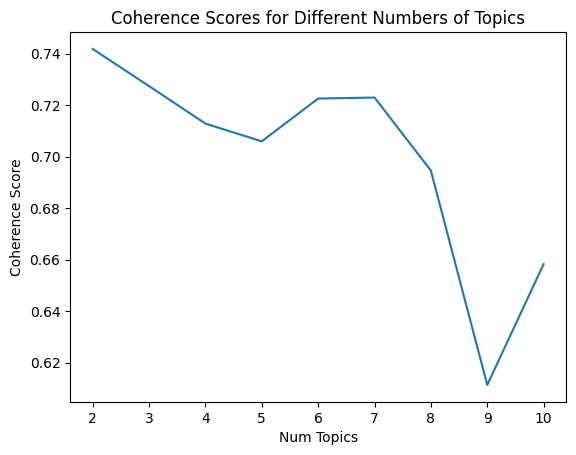

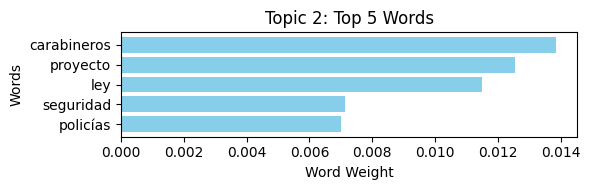

Constitution

    Optimal Number of Topics: 8 (Coherence Score = 0.537).
    Highlighted Topics:
        Topic 2: Constitutional reform and national identity (constitución, chile, hoy, país, nueva).
        Topic 6: Socio-political themes (constitución, proceso, social, chile, país).

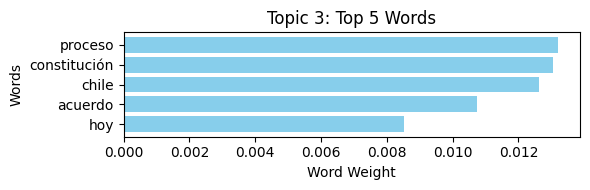

2. TF-IDF Analysis

TF-IDF highlights the most distinctive words used by coalitions in each debate:
Nain-Retamal Law

    Government Coalition: Words like votos, proyecto, seguridad reflect legislative priorities.
    Right Coalition: Words like carabineros, ley, chile emphasize enforcement and national security.

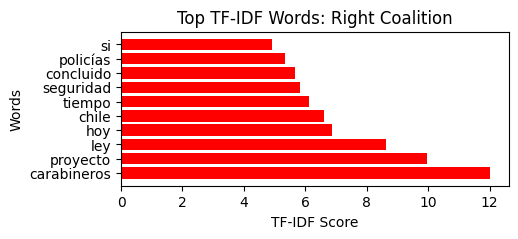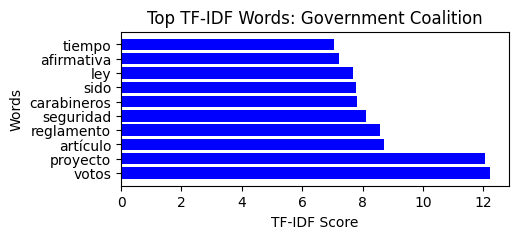

Constitution

    Government Coalition: Words like constitución, artículo, proceso focus on institutional priorities.
    Right Coalition: Words like punto, reglamento, constitución highlight procedural concerns.

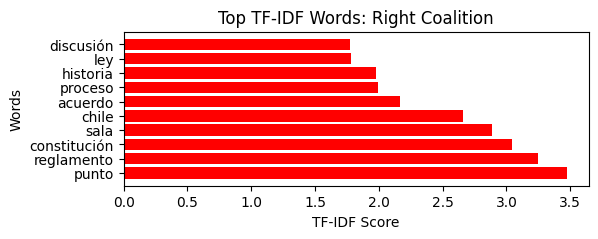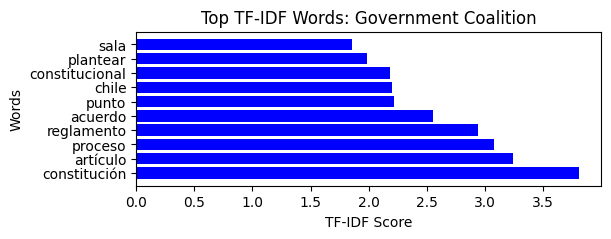


4. Sentiment Analysis

Sentiment scores provide insights into the tone of the debates across political categories:
Nain-Retamal Law

    Center (0.060) exhibits the most positive sentiment, contrasting with Right Wing (0.001), indicating polarized tones.

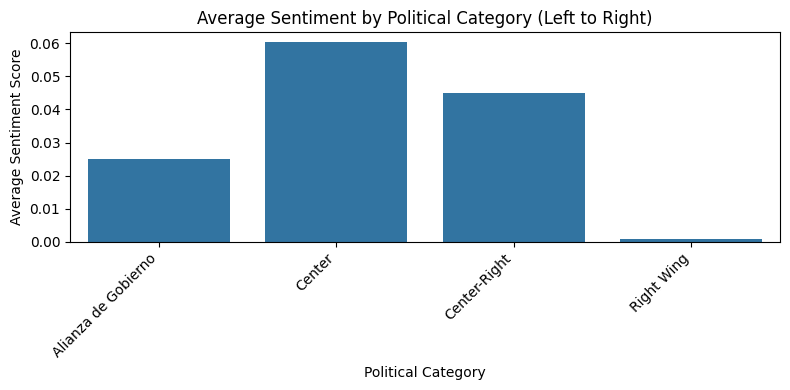

Constitution

    Alianza de Gobierno (0.050) shows the highest sentiment, reflecting optimism or constructive dialogue.
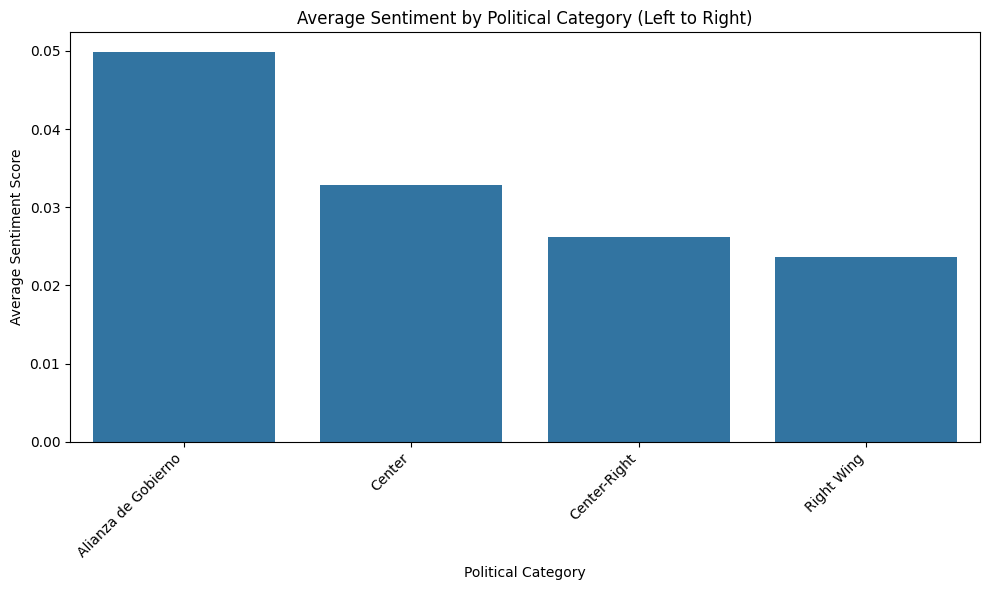

5. Conclusion

This analysis demonstrates the potential of NLP tools to extract insights from legislative debates quickly. While the results are not definitive, they showcase the capability to:

    Identify dominant themes and coalition-specific language.
    Provide sentiment and speech patterns for deeper analysis.

By scaling this tool or refining its processes, such analysis can offer meaningful contributions to understanding political discourse.